# 03 — Model Evaluation & Comparison

**Project:** Driver Drowsiness Detection System
**Goal of this notebook (Step 3):** measure **both** trained models on the **held-out test set** — images neither model has ever seen — and decide which one to deploy.

| | |
|---|---|
| **Input** | `model/saved_models/{custom_cnn,mobilenetv2}.keras`, `model/artifacts/history_*.json`, `data/processed/test/` (433 images) |
| **Output 1** | `model/results/metrics.json` — every number in this notebook |
| **Output 2** | `model/results/03_confusion_matrices.png` — confusion matrices of both models |

> **Run this notebook locally (CPU), not on Colab:** it measures **CPU inference speed**, which is what matters for the real-time webcam system. Evaluation itself is fast (433 images).

**Steps:** 1. Setup → 2. Configuration → 3. Test set → 4. Leakage flags → 5. Metric & speed functions → 6. Evaluate both models → 7. Comparison table → 8. Confusion matrices → 9. Per-class report → 10. Save metrics.json → 11. Recommendation

## 1. Setup

In [1]:
import json, time, datetime, platform
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from PIL import Image
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

# The notebook runs from the model/ folder, so the project root is one level up
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "model" else Path.cwd()
print("Project root:", PROJECT_ROOT)
print("TensorFlow  :", tf.__version__, "| Keras:", keras.__version__)
print("Device      :", tf.config.list_physical_devices("GPU") or f"CPU — {platform.processor()}")

Project root: D:\MyProj\Clg\DLL Proj1
TensorFlow  : 2.21.0 | Keras: 3.13.2


Device      : CPU — Intel64 Family 6 Model 140 Stepping 1, GenuineIntel


## 2. Configuration

Classes, image size and paths come from `data_config.json`. `MODELS` maps each saved model file to the name used in tables and plots.

In [2]:
MODEL_DIR     = PROJECT_ROOT / "model"
ARTIFACTS_DIR = MODEL_DIR / "artifacts"
SAVED_DIR     = MODEL_DIR / "saved_models"
RESULTS_DIR   = MODEL_DIR / "results"

data_config = json.loads((ARTIFACTS_DIR / "data_config.json").read_text())
CLASSES  = data_config["classes"]
IMG_SIZE = data_config["img_size"]
TEST_DIR = PROJECT_ROOT / data_config["paths"]["test"]
TRAIN_DIRS = [PROJECT_ROOT / data_config["paths"][s] for s in ("train", "val")]  # together = the official train split
NEAR_DUP_BITS = data_config["near_duplicate_test_images_in_train"]["threshold_bits"]

MODELS = {"custom_cnn": "Custom CNN", "mobilenetv2": "MobileNetV2"}
REALTIME_MS = 50  # real-time target per frame on CPU
print("Classes:", CLASSES, "| models:", list(MODELS.values()))

Classes: ['Closed', 'Open', 'no_yawn', 'yawn'] | models: ['Custom CNN', 'MobileNetV2']


## 3. Load the test set

The **official Kaggle test split**, untouched since notebook 01 — never used for training, validation or model selection.
`shuffle=False` keeps a fixed order, so every prediction lines up with its true label and its file path.

In [3]:
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, class_names=CLASSES, image_size=(IMG_SIZE, IMG_SIZE), shuffle=False)
file_paths = test_ds.file_paths
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
print("Test images per class:", {c: int((y_true == i).sum()) for i, c in enumerate(CLASSES)})

Found 433 files belonging to 4 classes.


Test images per class: {'Closed': 109, 'Open': 109, 'no_yawn': 109, 'yawn': 106}


## 4. Leakage flags (near-duplicates)

Notebook 01 found that about half of the `yawn` / `no_yawn` test images are near-identical video frames of training images. Here we flag those test images again with the **same dHash method and threshold**, so we can also report accuracy on the **leak-free** test images — the more honest estimate of how the model handles new people.

In [4]:
def dhash(path, size: int = 16) -> np.ndarray:
    # 256-bit difference-hash fingerprint (same as notebook 01).
    gray = np.asarray(Image.open(path).convert("L").resize((size + 1, size)), dtype=np.int16)
    return (gray[:, 1:] > gray[:, :-1]).flatten()


def near_duplicate_flags() -> np.ndarray:
    # True for each test image that has a near-duplicate training image of the same class.
    flags = np.zeros(len(file_paths), dtype=bool)
    for i, cls in enumerate(CLASSES):
        train_h = np.array([dhash(p) for d in TRAIN_DIRS for p in (d / cls).iterdir()])
        idx = np.where(y_true == i)[0]
        test_h = np.array([dhash(file_paths[j]) for j in idx])
        flags[idx] = (test_h[:, None, :] != train_h[None, :, :]).sum(axis=2).min(axis=1) <= NEAR_DUP_BITS
    return flags


leaked = near_duplicate_flags()
print("Near-duplicate test images per class:", {c: int(leaked[y_true == i].sum()) for i, c in enumerate(CLASSES)})
print(f"Leak-free test images: {(~leaked).sum()} of {len(leaked)}")

Near-duplicate test images per class: {'Closed': 0, 'Open': 0, 'no_yawn': 50, 'yawn': 52}
Leak-free test images: 331 of 433


## 5. Metric and speed functions

**Metrics** (all computed by scikit-learn from the true and predicted labels):

| Metric | Meaning |
|---|---|
| **Accuracy** | share of all test images classified correctly |
| **Precision** (per class) | of the images *predicted* as class X, how many really are X — high precision = few false alarms |
| **Recall** (per class) | of the images that *really are* X, how many were found — high recall = few misses. For `Closed`, recall is safety-critical: a missed closed eye is a missed drowsy driver |
| **F1-score** | harmonic mean of precision and recall — one number that is only high when both are high |
| **Macro average** | the plain average over the 4 classes, so every class counts equally |
| **Confusion matrix** | rows = true class, columns = predicted class; the diagonal holds the correct predictions |

**Speed:** median time for **one image** over 100 runs on this machine's CPU, after one warm-up call, using `predict_on_batch` — Keras' **compiled** prediction path, which is how the backend will call the model for each webcam frame. (Calling `model(x)` directly runs in *eager* mode, layer by layer from Python; that overhead hits deep networks hardest — measured here it made MobileNetV2 look 12× slower, 108 ms instead of 9 ms — so it would not be a fair comparison.)

In [5]:
def compute_metrics(y_pred: np.ndarray) -> dict:
    # Accuracy, macro + per-class precision/recall/F1, group accuracies and the confusion matrix.
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(len(CLASSES)), zero_division=0)
    eye = y_true <= 1  # Closed / Open are eye images; no_yawn / yawn are face frames
    acc = lambda mask: round(float(accuracy_score(y_true[mask], y_pred[mask])), 4)
    return {
        "accuracy": acc(np.ones_like(eye)),
        "precision_macro": round(float(p.mean()), 4),
        "recall_macro": round(float(r.mean()), 4),
        "f1_macro": round(float(f1.mean()), 4),
        "per_class": {c: {"precision": round(float(p[i]), 4), "recall": round(float(r[i]), 4), "f1": round(float(f1[i]), 4)}
                      for i, c in enumerate(CLASSES)},
        "accuracy_eye_classes": acc(eye),
        "accuracy_yawn_classes": acc(~eye),
        "accuracy_leak_free": acc(~leaked),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=range(len(CLASSES))).tolist(),
    }


def cpu_latency_ms(model: keras.Model, runs: int = 100) -> float:
    # Median milliseconds to classify ONE image with the compiled predict path (after a warm-up call).
    x = np.zeros((1, IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
    model.predict_on_batch(x)  # warm-up: builds the compiled prediction function
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        model.predict_on_batch(x)
        times.append(time.perf_counter() - start)
    return round(float(np.median(times)) * 1000, 2)

## 6. Evaluate both models

For each model: load it from disk, predict every test image, compute the metrics, measure CPU speed, and collect size and training facts from its history file.

In [6]:
results, predictions = {}, {}
for key, name in MODELS.items():
    path = SAVED_DIR / f"{key}.keras"
    model = keras.models.load_model(path)
    y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)
    hist = json.loads((ARTIFACTS_DIR / f"history_{key}.json").read_text())

    predictions[key] = y_pred
    results[key] = {
        "name": name,
        **compute_metrics(y_pred),
        "cpu_latency_ms": cpu_latency_ms(model),
        "parameters": model.count_params(),
        "file_size_mb": round(path.stat().st_size / 1e6, 2),
        "best_val_accuracy": round(hist["val_accuracy"][hist["best_epoch"] - 1], 4),
        "train_minutes": round(hist["train_seconds"] / 60, 1),
    }
    print(f"{name:<12} test accuracy {results[key]['accuracy']:.4f} | macro F1 {results[key]['f1_macro']:.4f} "
          f"| {results[key]['cpu_latency_ms']} ms/image")

Custom CNN   test accuracy 0.9861 | macro F1 0.9861 | 3.25 ms/image


MobileNetV2  test accuracy 0.9700 | macro F1 0.9698 | 8.86 ms/image


## 7. Side-by-side comparison

In [7]:
ROWS = [("Test accuracy", "accuracy", "{:.2%}"), ("Precision (macro)", "precision_macro", "{:.2%}"),
        ("Recall (macro)", "recall_macro", "{:.2%}"), ("F1-score (macro)", "f1_macro", "{:.2%}"),
        ("Accuracy — eye classes", "accuracy_eye_classes", "{:.2%}"),
        ("Accuracy — yawn classes", "accuracy_yawn_classes", "{:.2%}"),
        ("Accuracy — leak-free images", "accuracy_leak_free", "{:.2%}"),
        ("Best validation accuracy", "best_val_accuracy", "{:.2%}"),
        ("CPU latency (ms / image)", "cpu_latency_ms", "{:.1f}"), ("Parameters", "parameters", "{:,}"),
        ("File size (MB)", "file_size_mb", "{:.2f}"), ("Training time (min, GPU)", "train_minutes", "{:.1f}")]

print(f"{'Metric':<30}" + "".join(f"{results[k]['name']:>15}" for k in MODELS))
print("-" * (30 + 15 * len(MODELS)))
for label, key, fmt in ROWS:
    print(f"{label:<30}" + "".join(f"{fmt.format(results[k][key]):>15}" for k in MODELS))

Metric                             Custom CNN    MobileNetV2
------------------------------------------------------------
Test accuracy                          98.61%         97.00%
Precision (macro)                      98.62%         97.00%
Recall (macro)                         98.62%         96.99%
F1-score (macro)                       98.61%         96.98%
Accuracy — eye classes                 98.62%         99.54%
Accuracy — yawn classes                98.60%         94.42%
Accuracy — leak-free images            98.49%         97.89%
Best validation accuracy               99.19%         98.38%
CPU latency (ms / image)                  3.2            8.9
Parameters                            390,884      2,263,108
File size (MB)                           4.78          24.63
Training time (min, GPU)                  4.2            2.9


## 8. Confusion matrices

Rows are the **true** class, columns the **predicted** class. A perfect model has all images on the diagonal. Off-diagonal cells show exactly *which* mistakes a model makes — for example `Closed → Open` (a missed closed eye) is the most dangerous one for a drowsiness system.

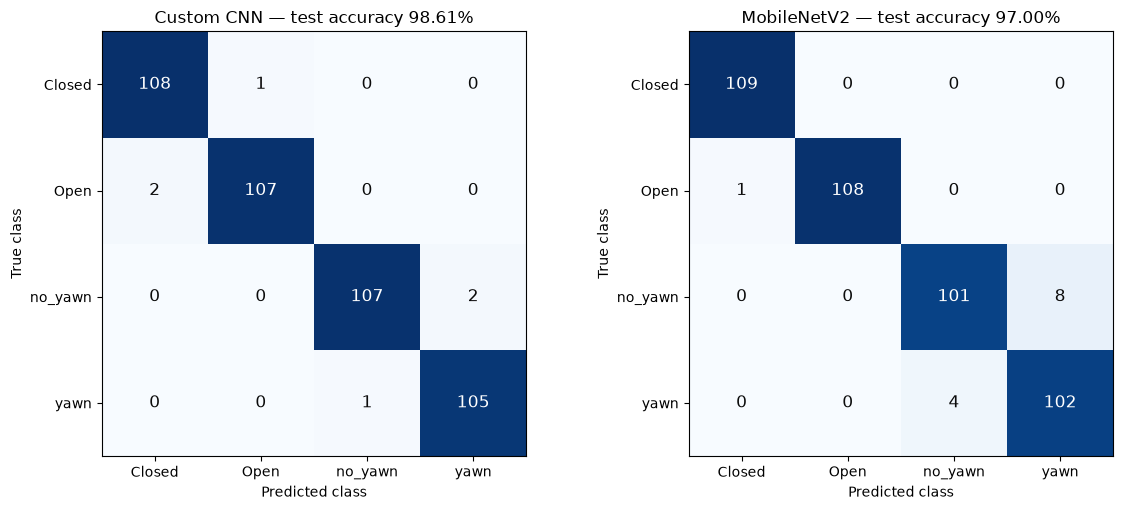

In [8]:
def plot_confusion_matrices(save_path: Path):
    # One confusion-matrix heatmap per model, with counts in every cell.
    fig, axes = plt.subplots(1, len(MODELS), figsize=(6 * len(MODELS), 5.2))
    for ax, key in zip(np.atleast_1d(axes), MODELS):
        cm = np.array(results[key]["confusion_matrix"])
        ax.imshow(cm, cmap="Blues")
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                        color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
        ax.set_xticks(range(len(CLASSES)), CLASSES)
        ax.set_yticks(range(len(CLASSES)), CLASSES)
        ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
        ax.set_title(f"{results[key]['name']} — test accuracy {results[key]['accuracy']:.2%}")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.show()


plot_confusion_matrices(RESULTS_DIR / "03_confusion_matrices.png")

## 9. Per-class report

Precision, recall and F1 for every class (scikit-learn's `classification_report`).

In [9]:
for key in MODELS:
    print(f"=== {results[key]['name']} ===")
    print(classification_report(y_true, predictions[key], target_names=CLASSES, digits=4))

=== Custom CNN ===
              precision    recall  f1-score   support

      Closed     0.9818    0.9908    0.9863       109
        Open     0.9907    0.9817    0.9862       109
     no_yawn     0.9907    0.9817    0.9862       109
        yawn     0.9813    0.9906    0.9859       106

    accuracy                         0.9861       433
   macro avg     0.9862    0.9862    0.9861       433
weighted avg     0.9862    0.9861    0.9861       433

=== MobileNetV2 ===
              precision    recall  f1-score   support

      Closed     0.9909    1.0000    0.9954       109
        Open     1.0000    0.9908    0.9954       109
     no_yawn     0.9619    0.9266    0.9439       109
        yawn     0.9273    0.9623    0.9444       106

    accuracy                         0.9700       433
   macro avg     0.9700    0.9699    0.9698       433
weighted avg     0.9703    0.9700    0.9700       433



## 10. Save all metrics

Everything above is written to `model/results/metrics.json`, together with the test-set size, the leakage counts and the software/hardware used — so every number in the README can be traced back to this file.

In [10]:
metrics = {
    "created": datetime.date.today().isoformat(),
    "test_images": int(len(y_true)),
    "near_duplicate_test_images": int(leaked.sum()),
    "classes": CLASSES,
    "hardware": f"CPU — {platform.processor()}",
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "models": results,
}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
print("Saved:", RESULTS_DIR / "metrics.json")

Saved: D:\MyProj\Clg\DLL Proj1\model\results\metrics.json


## 11. Recommendation

The deployment model must be **accurate on new people** (test and leak-free accuracy, especially recall for `Closed`) **and fast enough for real time** (under 50 ms per frame on CPU). The cell below prints the facts the decision is based on.

In [11]:
best = max(MODELS, key=lambda k: (results[k]["f1_macro"], -results[k]["cpu_latency_ms"]))
for key in MODELS:
    r = results[key]
    print(f"{r['name']:<12} macro F1 {r['f1_macro']:.4f} | leak-free acc {r['accuracy_leak_free']:.4f} | "
          f"Closed recall {r['per_class']['Closed']['recall']:.4f} | {r['cpu_latency_ms']} ms "
          f"({'real-time OK' if r['cpu_latency_ms'] < REALTIME_MS else 'TOO SLOW'})")
print(f"\nHighest macro F1: {results[best]['name']}")

Custom CNN   macro F1 0.9861 | leak-free acc 0.9849 | Closed recall 0.9908 | 3.25 ms (real-time OK)
MobileNetV2  macro F1 0.9698 | leak-free acc 0.9789 | Closed recall 1.0000 | 8.86 ms (real-time OK)

Highest macro F1: Custom CNN


### Result and recommendation → **Custom CNN** *(final choice confirmed by the user at the Step 3 checkpoint)*

| | Custom CNN | MobileNetV2 |
|---|---|---|
| Test accuracy / macro F1 | **98.61 % / 98.61 %** | 97.00 % / 96.98 % |
| Eye classes (drives the drowsiness alert) | 98.62 % (3 errors / 218) | **99.54 %** (1 error / 218) |
| Yawn classes | **98.60 %** | 94.42 % (12 errors / 215) |
| Leak-free test images | **98.49 %** | 97.89 % |
| CPU latency (compiled, 1 image) | **3.2 ms** | 8.9 ms |
| Size | **0.39 M params, 4.8 MB** | 2.26 M params, 24.6 MB |

**Why the Custom CNN:**
1. **Better overall** on unseen test images — higher accuracy and F1, and also on the leak-free subset, so the result is not inflated by near-duplicate frames.
2. **Much better at yawns** (98.6 % vs 94.4 %): MobileNetV2 confuses `no_yawn` ↔ `yawn` 12 times; the CNN only 3 times.
3. **~3× faster and ~5× smaller** — more headroom for real-time use alongside face/eye detection in the backend.
4. MobileNetV2 is slightly better on the eye classes (1 vs 3 errors out of 218). That gap is too small to be meaningful on this test size, and the backend's alert needs eyes to stay closed over many frames, so a single misread frame does not trigger or block an alert.

**Both models meet the real-time target** (< 50 ms per frame on CPU), so either could be deployed.